# Task 1: FER2013 baseline: 3 classifiers × 3 feature types

**Question:** which classifier and which features recognise emotions best on FER2013, and where do they fail?

| Step | What we do | Uses |
|---|---|---|
| 1 | Load the data | train + validation |
| 2 | Extract features (HOG, landmarks, PCA-pixels) | train + validation |
| 3 | Train all 9 combinations, score them | train → validation |
| 4 | Look at mistakes: confusion matrices, hardest emotions, bad images | validation |
| 5 | *(optional)* Check feature settings (PCA size, HOG cell size) | validation |
| 6 | Tune each classifier | validation |
| 7 | **Final test**, once | PrivateTest |
| 8 | Check data quality (duplicate images) | all splits |

**Rules of the assignment:** train on `train`, choose models and hyperparameters on `validation` (PublicTest), and touch `test` (PrivateTest) only once, at the very end.

**Before you run:** `fer_features.py` must sit next to this notebook, the split CSVs must exist in `data/fer/`
(run the split notebook first), and the dlib model must be in `models/faceAndLandmarkModels/`.

## 0. Setup

In [1]:
import os, sys, time, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from pathlib import Path
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)

# ----- settings you may want to change ---------------------------------------------------
RANDOM_STATE   = 42
PCA_COMPONENTS = 100        # PCA size (see section 5 for the sweep)
CLASS_WEIGHT   = None       # plain baseline. Try "balanced" later (Task 5)
SVM_SUBSAMPLE  = None       # e.g. 8000 for a quick dry run; None = all training data (slow: minutes)
RUN_FINAL_TEST = True      # set True ONCE, when every choice above is final
FORCE_RETRAIN = False      # False = reuse saved results and models when they exist; True = recompute everything

# ----- folders ---------------------------------------------------------------------------
# Find the repository root from wherever Jupyter starts (the notebook's own folder).
ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "auxFiles/kdef_subject_split.pkl").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "fer"
FEAT_DIR  = os.path.join(DATA, "features")
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"

# Create the output folders if they do not exist yet (they are git-ignored, so new clones lack them).
for folder in (FEAT_DIR, FIG_DIR, MODEL_DIR):
    os.makedirs(folder, exist_ok=True)

from scripts.fer_features import EMOTIONS, HOG_PARAMS, FEATURE_FNS      # feature code shared with the demo

CLASSIFIERS = ["LogReg", "SVM", "RF"]
N_JOBS = max(1, (os.cpu_count() or 2) - 1)


## 1. Load the data
Only `train` and `validation` are loaded here. Each image is a 48×48 grayscale face.

 emotion  train  validation
   Angry   3995         467
 Disgust    436          56
    Fear   4097         496
   Happy   7215         895
     Sad   4830         653
Surprise   3171         415
 Neutral   4965         607


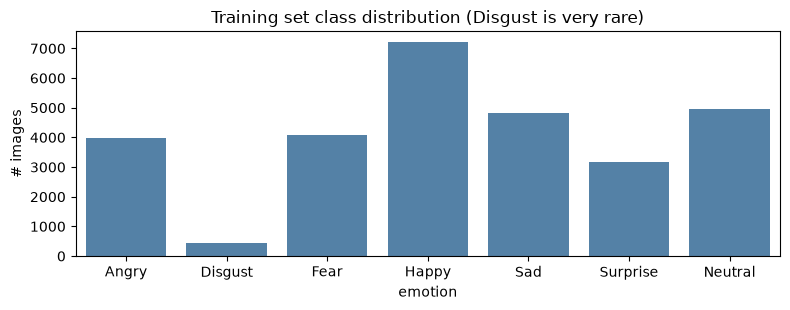

In [2]:
def load_split(name):
    """Read data/fer/fer2013_<name>.csv -> (images as uint8 [N,48,48], labels [N])."""
    df = pd.read_csv(os.path.join(DATA, f"fer2013_{name}.csv"))
    images = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in df["pixels"]])
    return images, df["emotion"].values

img_train, y_train = load_split("train")
img_val,   y_val   = load_split("validation")

counts = pd.DataFrame({"emotion": EMOTIONS,
                       "train": np.bincount(y_train, minlength=7),
                       "validation": np.bincount(y_val, minlength=7)})
print(counts.to_string(index=False))

plt.figure(figsize=(8, 3.2))
sns.barplot(data=counts, x="emotion", y="train", color="steelblue")
plt.title("Training set class distribution (Disgust is very rare)"); plt.ylabel("# images")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fer_class_distribution.png"), dpi=150); plt.show()

## 2. Features

| Feature | What it captures | Size |
|---|---|---|
| **HOG** | local edge directions (mouth, eyes, brows) | 900 |
| **Landmarks** | positions of 68 face points (dlib), normalised | 136 |
| **PCA** | raw pixels compressed to the main directions of variation (PCA is fitted *inside* the model pipeline, on training data only, so nothing leaks) | 100 |

The extraction code lives in `fer_features.py`. Results are cached in `data/fer/features/`.
**If you change a feature setting, delete that folder.**

In [3]:
def cached_features(feature, images, split):
    """Compute features once and reuse them from disk afterwards."""
    cache_name, extract = FEATURE_FNS[feature]
    path = os.path.join(FEAT_DIR, f"{cache_name}_{split}.npy")
    if os.path.exists(path):
        return np.load(path)
    t = time.time(); X = extract(images); np.save(path, X)
    print(f"  computed {feature}/{split}: {X.shape} in {time.time() - t:.0f}s")
    return X

FEATURES = {f: (cached_features(f, img_train, "train"), cached_features(f, img_val, "validation"))
            for f in FEATURE_FNS}
for f, (Xtr, Xva) in FEATURES.items():
    print(f"{f:10s} train {Xtr.shape}   validation {Xva.shape}")

  computed HOG/train: (28709, 900) in 10s
  computed HOG/validation: (3589, 900) in 1s
  computed Landmarks/train: (28709, 136) in 40s
  computed Landmarks/validation: (3589, 136) in 5s
  computed PCA/train: (28709, 2304) in 0s
  computed PCA/validation: (3589, 2304) in 0s
HOG        train (28709, 900)   validation (3589, 900)
Landmarks  train (28709, 136)   validation (3589, 136)
PCA        train (28709, 2304)   validation (3589, 2304)


## 3. Models and metrics
`make_model` builds a scikit-learn pipeline: (PCA *or* scaler) → classifier.
Logistic Regression and SVM need scaled inputs; Random Forest does not.

We report three metrics:
- **accuracy** — share correct; dominated by the big classes (Happy, Neutral, Sad)
- **balanced accuracy** — average recall per class; every emotion counts equally
- **macro-F1** — average F1 per class; punishes failures on rare classes. *We rank models by this one.*

In [4]:
def make_model(clf_name, feat_name, **params):
    """Pipeline for one (classifier, feature) pair. `params` override the classifier defaults."""
    steps = []
    if feat_name == "PCA":
        steps.append(("pca", PCA(n_components=PCA_COMPONENTS, whiten=True, random_state=RANDOM_STATE)))
    elif clf_name in ("LogReg", "SVM"):
        steps.append(("scaler", StandardScaler()))

    if clf_name == "LogReg":
        kw = dict(C=1.0, max_iter=2000, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = LogisticRegression(**kw)
    elif clf_name == "SVM":
        kw = dict(kernel="rbf", C=1.0, gamma="scale", cache_size=1000,
                  class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = SVC(**kw)
    elif clf_name == "RF":
        kw = dict(n_estimators=300, max_depth=None, max_features="sqrt", n_jobs=-1,
                  class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = RandomForestClassifier(**kw)
    else:
        raise ValueError(clf_name)
    steps.append(("clf", clf))
    return Pipeline(steps)

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, average="macro"))

## 4. The 3 × 3 experiment (train → validation)
All nine combinations with default settings. The RBF-SVM is the slow one, especially on HOG
(several minutes). Use `SVM_SUBSAMPLE = 8000` in the setup cell for a quick first run.

In [5]:
VAL_RESULTS_FILE = os.path.join(FIG_DIR, "task1_validation_results.csv")
VAL_PRED_FILE = os.path.join(FIG_DIR, "task1_validation_predictions.pkl")

if os.path.exists(VAL_RESULTS_FILE) and os.path.exists(VAL_PRED_FILE) and not FORCE_RETRAIN:
    # Reuse the results from the last run instead of fitting the nine models again.
    results = pd.read_csv(VAL_RESULTS_FILE)
    val_pred = joblib.load(VAL_PRED_FILE)
    fitted = {}   # cell 17 loads or fits the one model it needs
    print("Loaded saved validation results (set FORCE_RETRAIN = True to recompute)")
else:
    rows, fitted, val_pred = [], {}, {}
    rng = np.random.RandomState(RANDOM_STATE)

    for feat, (Xtr, Xva) in FEATURES.items():
        for clf in CLASSIFIERS:
            idx = np.arange(len(Xtr))
            if clf == "SVM" and SVM_SUBSAMPLE:
                idx = rng.choice(len(Xtr), SVM_SUBSAMPLE, replace=False)
            t = time.time(); model = make_model(clf, feat).fit(Xtr[idx], y_train[idx]); fit_s = time.time() - t
            y_pred = model.predict(Xva)
            fitted[(feat, clf)], val_pred[(feat, clf)] = model, y_pred
            rows.append(dict(features=feat, classifier=clf, **scores(y_val, y_pred), fit_seconds=round(fit_s, 1)))
            print(f"{feat:10s} {clf:7s} macro-F1={rows[-1]['macro_f1']:.3f}  acc={rows[-1]['accuracy']:.3f}  ({fit_s:.0f}s)")

    results = pd.DataFrame(rows)
    results.to_csv(VAL_RESULTS_FILE, index=False)
    joblib.dump(val_pred, VAL_PRED_FILE)


Loaded saved validation results (set FORCE_RETRAIN = True to recompute)


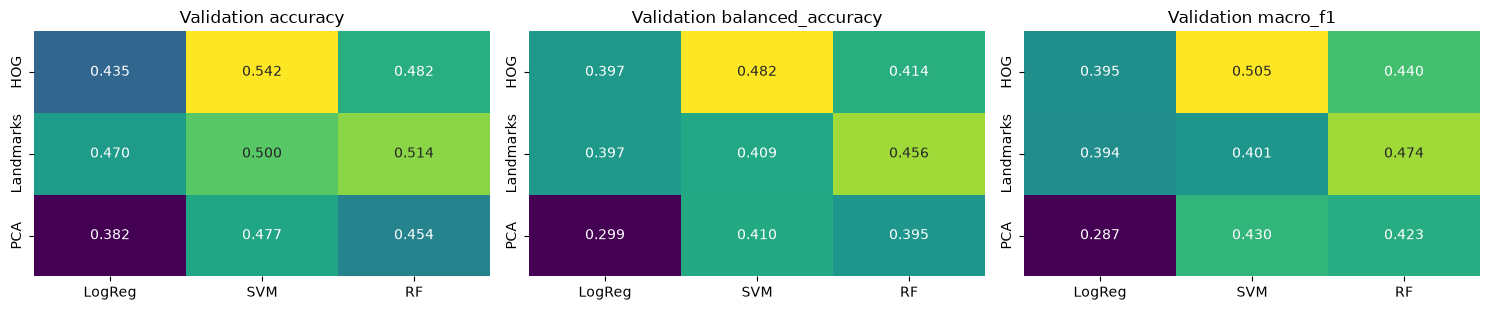

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, metric in zip(axes, ["accuracy", "balanced_accuracy", "macro_f1"]):
    table = results.pivot(index="features", columns="classifier", values=metric)[CLASSIFIERS]
    sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(f"Validation {metric}"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_metric_heatmaps.png"), dpi=150); plt.show()

## 5. Where do the models go wrong?
**Confusion matrices** (appendix figure): each row is the true emotion and sums to 1; the diagonal is the share
classified correctly, and off-diagonal cells show which emotion it was mistaken for.

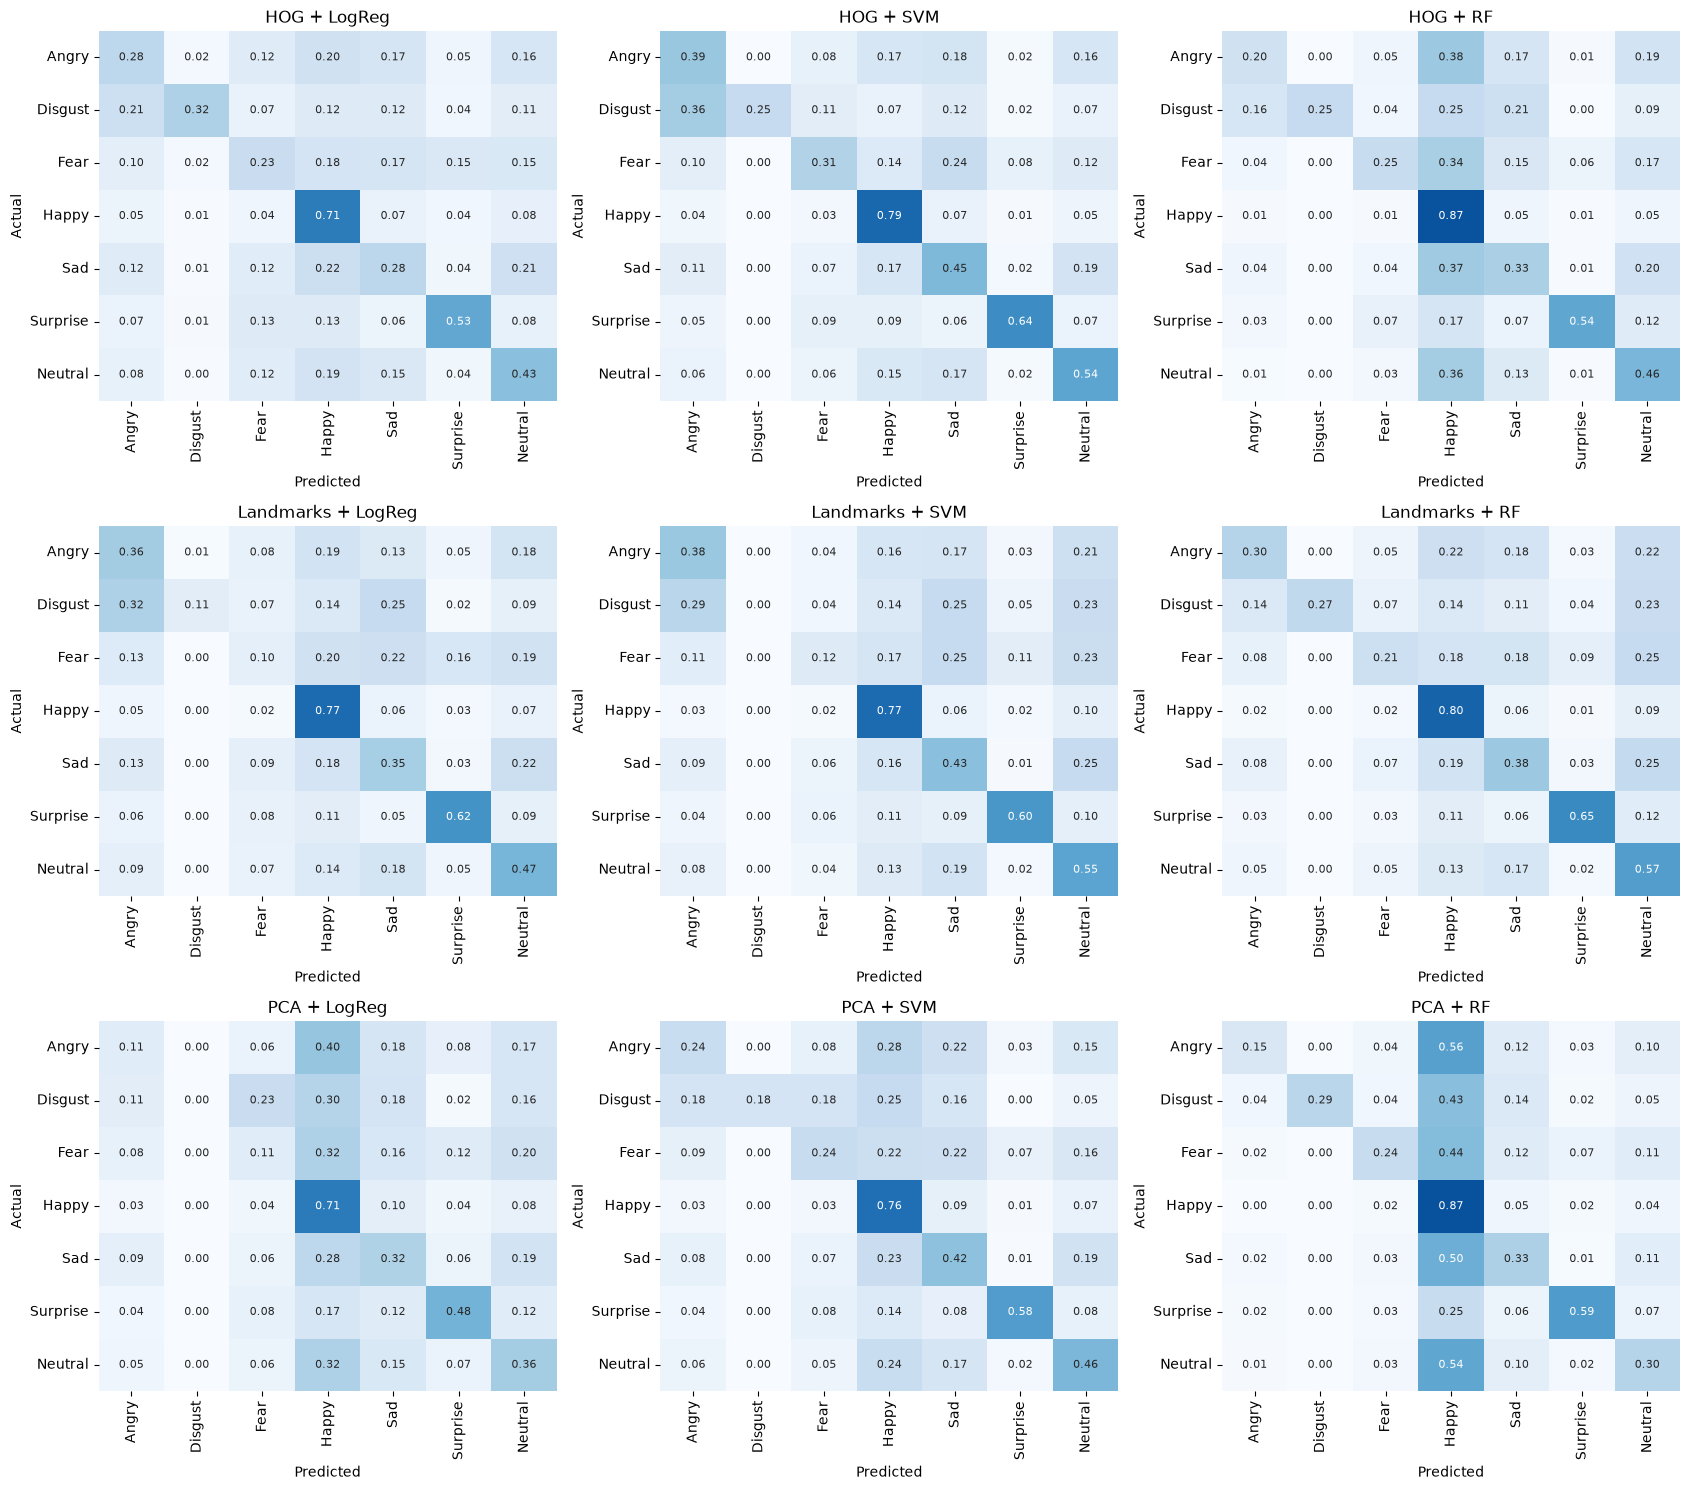

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for i, feat in enumerate(FEATURES):
    for j, clf in enumerate(CLASSIFIERS):
        cm = confusion_matrix(y_val, val_pred[(feat, clf)], labels=range(7), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=axes[i, j], annot_kws={"size": 8})
        axes[i, j].set_title(f"{feat} + {clf}"); axes[i, j].set_xlabel("Predicted"); axes[i, j].set_ylabel("Actual")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_confusion_matrices_val.png"), dpi=150); plt.show()

**Hardest emotions:** F1 per emotion for each model. Low values mean hard. Then the best configuration and its most frequent confusions.

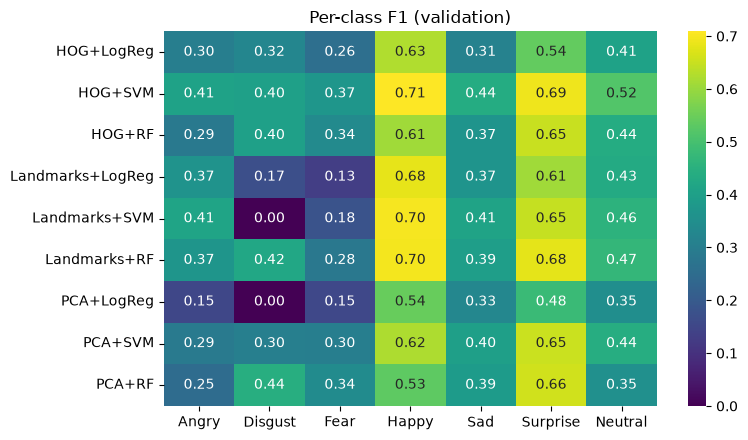

Mean F1 per emotion over all 9 models (low = hard):
Fear        0.262
Disgust     0.274
Angry       0.315
Sad         0.378
Neutral     0.429
Surprise    0.623
Happy       0.635

Best on validation: HOG + SVM

              precision    recall  f1-score   support

       Angry      0.433     0.388     0.409       467
     Disgust      1.000     0.250     0.400        56
        Fear      0.453     0.315     0.371       496
       Happy      0.645     0.787     0.709       895
         Sad      0.423     0.452     0.437       653
    Surprise      0.751     0.641     0.692       415
     Neutral      0.491     0.542     0.515       607

    accuracy                          0.542      3589
   macro avg      0.600     0.482     0.505      3589
weighted avg      0.542     0.542     0.534      3589

Most frequent confusions (true -> predicted):
  Fear      -> Sad        121  (24% of all Fear)
  Sad       -> Neutral    121  (19% of all Sad)
  Sad       -> Happy      108  (17% of all Sad)
  

In [8]:
per_class = pd.DataFrame({f"{f}+{c}": f1_score(y_val, val_pred[(f, c)], average=None, labels=range(7))
                          for f in FEATURES for c in CLASSIFIERS}, index=EMOTIONS).T
plt.figure(figsize=(8, 4.5))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="viridis")
plt.title("Per-class F1 (validation)"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "task1_per_class_f1.png"), dpi=150); plt.show()
print("Mean F1 per emotion over all 9 models (low = hard):")
print(per_class.mean().sort_values().round(3).to_string())

# ---- best default configuration (by validation macro-F1) ----
best = results.sort_values("macro_f1", ascending=False).iloc[0]
BEST_FEAT, BEST_CLF = best["features"], best["classifier"]
print(f"\nBest on validation: {BEST_FEAT} + {BEST_CLF}\n")
print(classification_report(y_val, val_pred[(BEST_FEAT, BEST_CLF)], target_names=EMOTIONS, digits=3))

cm = confusion_matrix(y_val, val_pred[(BEST_FEAT, BEST_CLF)], labels=range(7))
confusions = [(EMOTIONS[i], EMOTIONS[j], cm[i, j], cm[i, j] / cm[i].sum())
              for i in range(7) for j in range(7) if i != j]
print("Most frequent confusions (true -> predicted):")
for t, p, n, frac in sorted(confusions, key=lambda r: -r[2])[:6]:
    print(f"  {t:9s} -> {p:9s} {n:4d}  ({frac:.0%} of all {t})")

**Evidence from the images themselves.** Left: does the error rate depend on image brightness or contrast?
Right: the most confident *wrong* predictions of the best model. Look for mislabelled faces, occlusions, watermarks, non-faces and extreme lighting.

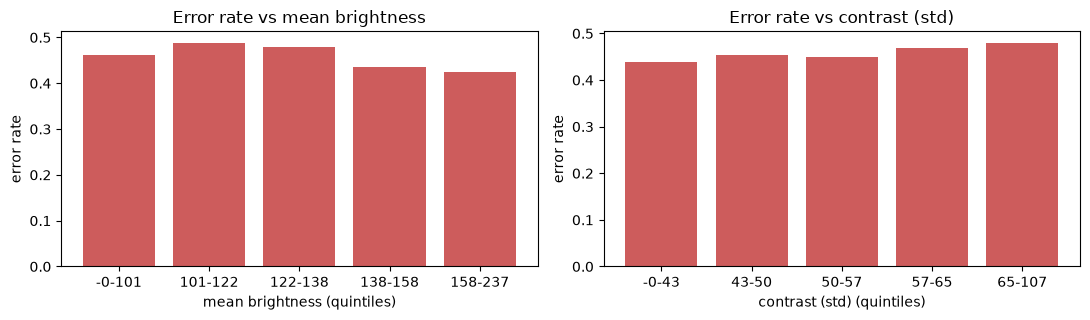

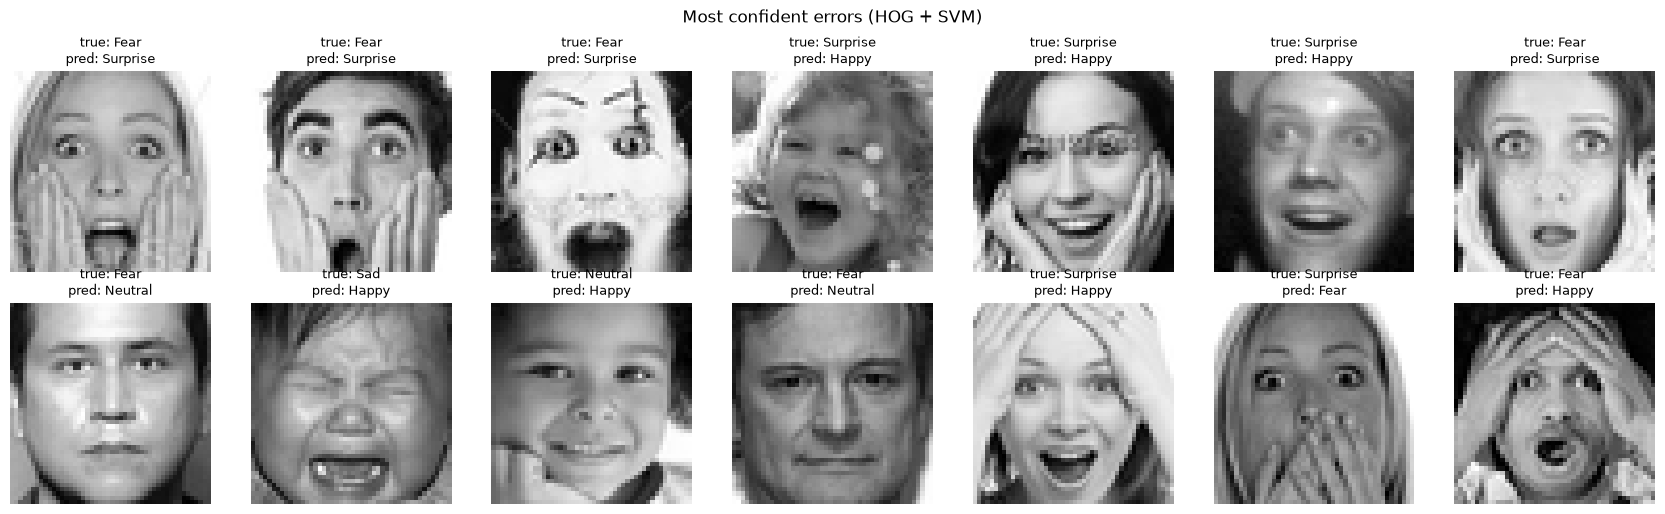

In [9]:
# The validation model for the best configuration: reuse the saved copy, or fit it once and save it.
best_path = os.path.join(MODEL_DIR, f"fer_validation_{BEST_FEAT.lower()}_{BEST_CLF.lower()}.pkl")
if (BEST_FEAT, BEST_CLF) in fitted:
    best_model = fitted[(BEST_FEAT, BEST_CLF)]
    joblib.dump(best_model, best_path)   # keep a copy so later runs can skip the fit
elif os.path.exists(best_path) and not FORCE_RETRAIN:
    best_model = joblib.load(best_path)
else:
    best_model = make_model(BEST_CLF, BEST_FEAT).fit(FEATURES[BEST_FEAT][0], y_train)
    joblib.dump(best_model, best_path)
y_pred_best = val_pred[(BEST_FEAT, BEST_CLF)]
wrong = y_pred_best != y_val

# (a) error rate by brightness / contrast quintile
flat = img_val.reshape(len(img_val), -1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for ax, vals, name in zip(axes, [flat.mean(axis=1), flat.std(axis=1)], ["mean brightness", "contrast (std)"]):
    bins = pd.qcut(vals, 5, duplicates="drop")
    err = pd.Series(wrong).groupby(bins, observed=True).mean()
    ax.bar(range(len(err)), err.values, color="indianred")
    ax.set_xticks(range(len(err))); ax.set_xticklabels([f"{iv.left:.0f}-{iv.right:.0f}" for iv in err.index])
    ax.set_xlabel(name + " (quintiles)"); ax.set_ylabel("error rate"); ax.set_title(f"Error rate vs {name}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_error_vs_lighting.png"), dpi=150); plt.show()

# (b) most confident errors. An SVC has no predict_proba, so use its decision score instead.
final_step, Xva_best = best_model.steps[-1][1], FEATURES[BEST_FEAT][1]
if hasattr(final_step, "predict_proba"):
    conf = best_model.predict_proba(Xva_best)[np.arange(len(y_val)), y_pred_best]
else:
    conf = best_model.decision_function(Xva_best)[np.arange(len(y_val)), y_pred_best]
worst = np.argsort(-np.where(wrong, conf, -np.inf))[:14]

fig, axes = plt.subplots(2, 7, figsize=(17, 5.2))
for ax, k in zip(axes.ravel(), worst):
    ax.imshow(img_val[k], cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {EMOTIONS[y_val[k]]}\npred: {EMOTIONS[y_pred_best[k]]}", fontsize=9)
plt.suptitle(f"Most confident errors ({BEST_FEAT} + {BEST_CLF})")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_hard_examples.png"), dpi=150); plt.show()

## 7. Tune every classifier (validation only)
Each classifier is tuned on the feature set where it did best in section 4, so the comparison is not just "tuned winner vs default rest".
- the SVM grid includes `C` and `gamma` and tunes on a subsample for speed;
- the Random Forest grid limits depth and leaf size, because the RF overfits duplicates (see section 9);
- the best settings are then **refit on the full training set** and scored on validation.

In [10]:
import ast
TUNE_N_SVM = 10000      # SVM tuning subsample; the final refit uses ALL training data

def grid_for(clf, n_inputs):
    if clf == "LogReg":
        return {"C": [0.01, 0.1, 1, 10]}
    if clf == "SVM":
        g0 = 1.0 / n_inputs                 # = sklearn's gamma="scale" for unit-variance inputs
        return {"C": [1, 5, 10], "gamma": [g0 * 0.5, g0, g0 * 2]}
    return {"max_depth": [None, 25], "min_samples_leaf": [1, 3, 5]}       # RF

def try_params(params, clf, feat, Xt, yt, Xv, yv):
    extra = {"n_jobs": 1} if clf == "RF" else {}                          # avoid nested parallelism
    return scores(yv, make_model(clf, feat, **params, **extra).fit(Xt, yt).predict(Xv))

TUNED, tuned_rows = {}, []
TUNED_FILE = os.path.join(FIG_DIR, "task1_tuned_validation_results.csv")
saved = pd.read_csv(TUNED_FILE) if os.path.exists(TUNED_FILE) else None
saved_models_exist = saved is not None and all(
    os.path.exists(os.path.join(MODEL_DIR, f"fer_{f.lower()}_{c.lower()}.pkl"))
    for f, c in zip(saved["features"], saved["classifier"]))

if saved_models_exist and not FORCE_RETRAIN:
    # Reuse the tuned settings and the models saved by the test step (cell 21).
    for _, row in saved.iterrows():
        clf, feat = row["classifier"], row["features"]
        TUNED[clf] = dict(feat=feat, params=ast.literal_eval(row["params"]),
                          model=joblib.load(os.path.join(MODEL_DIR, f"fer_{feat.lower()}_{clf.lower()}.pkl")))
        tuned_rows.append(row.to_dict())
        print(f"{clf:7s} (saved) on {feat:9s} {TUNED[clf]['params']}   "
              f"val macro-F1 {row['macro_f1_default']:.3f} -> {row['macro_f1_tuned']:.3f}")
else:
    for clf in CLASSIFIERS:
        feat = results[results.classifier == clf].sort_values("macro_f1", ascending=False).iloc[0]["features"]
        Xtr, Xva = FEATURES[feat]
        n_inputs = PCA_COMPONENTS if feat == "PCA" else Xtr.shape[1]
        grid = list(ParameterGrid(grid_for(clf, n_inputs)))

        use = np.arange(len(Xtr))
        if clf == "SVM" and TUNE_N_SVM < len(Xtr):
            use = np.random.RandomState(RANDOM_STATE).choice(len(Xtr), TUNE_N_SVM, replace=False)
        grid_scores = Parallel(n_jobs=N_JOBS)(
            delayed(try_params)(p, clf, feat, Xtr[use], y_train[use], Xva, y_val) for p in grid)
        best_params = grid[int(np.argmax([s["macro_f1"] for s in grid_scores]))]

        t = time.time(); model = make_model(clf, feat, **best_params).fit(Xtr, y_train); fit_s = time.time() - t
        sc = scores(y_val, model.predict(Xva))
        default_f1 = results[(results.features == feat) & (results.classifier == clf)].iloc[0]["macro_f1"]
        TUNED[clf] = dict(feat=feat, params=best_params, model=model)
        tuned_rows.append(dict(classifier=clf, features=feat, params=str(best_params),
                               macro_f1_default=default_f1, macro_f1_tuned=sc["macro_f1"],
                               accuracy=sc["accuracy"], balanced_accuracy=sc["balanced_accuracy"],
                               fit_seconds=round(fit_s, 1)))
        print(f"{clf:7s} on {feat:9s} {best_params}   val macro-F1 {default_f1:.3f} -> {sc['macro_f1']:.3f}")

tuned_df = pd.DataFrame(tuned_rows)
tuned_df.to_csv(os.path.join(FIG_DIR, "task1_tuned_validation_results.csv"), index=False)
tuned_df.round(3)

LogReg  on HOG       {'C': 0.01}   val macro-F1 0.395 -> 0.411
SVM     on HOG       {'C': 10, 'gamma': 0.0011111111111111111}   val macro-F1 0.505 -> 0.562
RF      on Landmarks {'max_depth': 25, 'min_samples_leaf': 1}   val macro-F1 0.474 -> 0.474


,classifier,features,params,macro_f1_default,macro_f1_tuned,accuracy,balanced_accuracy,fit_seconds
0,LogReg,HOG,{'C': 0.01},0.395,0.411,0.451,0.402,22.5
1,SVM,HOG,"{'C': 10, 'gamma': 0.0011111111111111111}",0.505,0.562,0.570,0.540,963.9
2,RF,Landmarks,"{'max_depth': 25, 'min_samples_leaf': 1}",0.474,0.474,0.515,0.455,6.0


## 8. Final evaluation on the test split (PrivateTest)
The model list is fixed by **validation** (section 7). Run this **once**, then do not change any model.
It reports metrics, confusion matrices and bootstrap confidence intervals, saves the `.pkl` files, and measures prediction speed.
Set `RUN_FINAL_TEST = True` in the setup cell first.

  computed HOG/test: (3589, 900) in 1s
  computed Landmarks/test: (3589, 136) in 5s


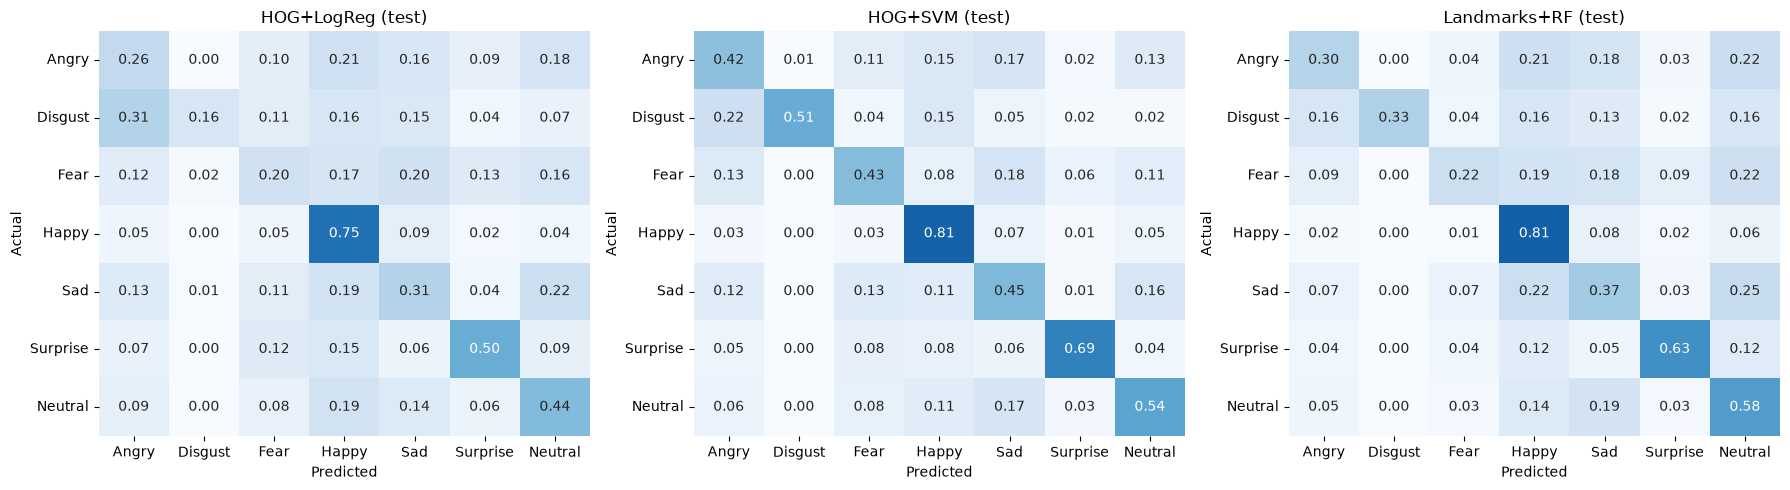

,model,params,accuracy,balanced_accuracy,macro_f1
0,HOG+LogReg,{'C': 0.01},0.438,0.376,0.378
1,HOG+SVM,"{'C': 10, 'gamma': 0.0011111111111111111}",0.575,0.550,0.568
2,Landmarks+RF,"{'max_depth': 25, 'min_samples_leaf': 1}",0.513,0.463,0.482


,Angry,Disgust,Fear,Happy,Sad,Surprise,Neutral
HOG+LogReg,0.288,0.214,0.235,0.646,0.316,0.513,0.431
HOG+SVM,0.438,0.622,0.458,0.754,0.433,0.728,0.545
Landmarks+RF,0.373,0.493,0.311,0.690,0.361,0.654,0.492


In [11]:
if RUN_FINAL_TEST:
    img_test, y_test = load_split("test")
    TEST_PRED, test_rows, test_f1 = {}, [], {}

    for clf, t in TUNED.items():
        name = f"{t['feat']}+{clf}"
        X_test = cached_features(t["feat"], img_test, "test")
        y_hat = t["model"].predict(X_test)
        TEST_PRED[name] = y_hat
        test_rows.append(dict(model=name, params=str(t["params"]), **scores(y_test, y_hat)))
        test_f1[name] = f1_score(y_test, y_hat, average=None, labels=range(7))
        joblib.dump(t["model"], os.path.join(MODEL_DIR, f"fer_{t['feat'].lower()}_{clf.lower()}.pkl"))

    test_df = pd.DataFrame(test_rows)
    test_f1 = pd.DataFrame(test_f1, index=EMOTIONS).T
    test_df.to_csv(os.path.join(FIG_DIR, "task1_test_results.csv"), index=False)
    test_f1.to_csv(os.path.join(FIG_DIR, "task1_test_per_class_f1.csv"))

    fig, axes = plt.subplots(1, len(TEST_PRED), figsize=(6 * len(TEST_PRED), 5))
    for ax, (name, y_hat) in zip(np.atleast_1d(axes), TEST_PRED.items()):
        cm = confusion_matrix(y_test, y_hat, labels=range(7), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax)
        ax.set_title(f"{name} (test)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_confusion_test.png"), dpi=150); plt.show()
    display(test_df.round(3)); display(test_f1.round(3))
else:
    print("Skipped: set RUN_FINAL_TEST = True in the setup cell when you are ready.")

**How certain are the test numbers, and how fast are the models?** Bootstrap 95% intervals (same resamples for every model, so differences are paired), and per-image prediction time, which matters for the webcam demo.

In [12]:
if RUN_FINAL_TEST:
    rng = np.random.RandomState(0)
    resamples = rng.randint(0, len(y_test), (1000, len(y_test)))
    boot = {n: np.array([f1_score(y_test[r], p[r], average="macro") for r in resamples]) for n, p in TEST_PRED.items()}

    print("Test macro-F1 with 95% bootstrap interval")
    for n, b in boot.items():
        print(f"  {n:18s} {f1_score(y_test, TEST_PRED[n], average='macro'):.3f}  [{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]")
    names = list(boot)
    print("Differences in macro-F1 (interval excluding 0 = unlikely to be noise)")
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            d = boot[names[i]] - boot[names[j]]
            print(f"  {names[i]:18s} - {names[j]:18s} {d.mean():+.3f}  [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")

    def ms_per_call(fn, n):
        t0 = time.time()
        for i in range(n): fn(i)
        return (time.time() - t0) / n * 1000
    speed = []
    for clf, t in TUNED.items():
        X_test, extract = cached_features(t["feat"], img_test, "test"), FEATURE_FNS[t["feat"]][1]
        N = len(X_test)
        speed.append(dict(model=f"{t['feat']}+{clf}",
                          predict_ms=round(ms_per_call(lambda i: t["model"].predict(X_test[i % N:i % N + 1]), 200), 2),
                          feature_extraction_ms=round(ms_per_call(lambda i: extract(img_test[i % N:i % N + 1]), 50), 2),
                          fit_seconds=float(tuned_df.set_index("classifier").loc[clf, "fit_seconds"])))
    speed = pd.DataFrame(speed); speed.to_csv(os.path.join(FIG_DIR, "task1_speed.csv"), index=False); display(speed)

Test macro-F1 with 95% bootstrap interval
  HOG+LogReg         0.378  [0.355, 0.400]
  HOG+SVM            0.568  [0.544, 0.590]
  Landmarks+RF       0.482  [0.457, 0.507]
Differences in macro-F1 (interval excluding 0 = unlikely to be noise)
  HOG+LogReg         - HOG+SVM            -0.191  [-0.214, -0.167]
  HOG+LogReg         - Landmarks+RF       -0.105  [-0.133, -0.076]
  HOG+SVM            - Landmarks+RF       +0.086  [+0.062, +0.111]


,model,predict_ms,feature_extraction_ms,fit_seconds
0,HOG+LogReg,0.18,0.37,22.5
1,HOG+SVM,14.17,0.44,963.9
2,Landmarks+RF,67.61,2.00,6.0


## 9. Data-quality check: duplicate images
FER2013 contains exact copies of images across splits (and some copies with *different* labels, which is direct evidence of label noise).
Models that memorise, such as a deep Random Forest or an SVM, look better than they really are on duplicated images.
Below: how much does each model's validation macro-F1 drop when duplicated images are excluded?

In [13]:
def md5(im): return hashlib.md5(im.tobytes()).hexdigest()

train_labels = {}
for im, y in zip(img_train, y_train):
    train_labels.setdefault(md5(im), set()).add(y)

# validation: all nine models, with and without duplicated images
not_dup = np.array([md5(im) not in train_labels for im in img_val])
print(f"validation images that also appear in train: {(~not_dup).sum()} of {len(not_dup)}")
dedup = pd.DataFrame([dict(model=f"{f}+{c}", f1_all=f1_score(y_val, p, average="macro"),
                           f1_dedup=f1_score(y_val[not_dup], p[not_dup], average="macro"))
                      for (f, c), p in val_pred.items()])
dedup["drop"] = dedup.f1_all - dedup.f1_dedup
display(dedup.sort_values("f1_dedup", ascending=False).round(3))

# test: only for the tuned models, and only if the final test has been run
if RUN_FINAL_TEST:
    test_hash = [md5(im) for im in img_test]
    dup = np.array([h in train_labels for h in test_hash])
    same_label = np.array([dup[i] and y_test[i] in train_labels[test_hash[i]] for i in range(len(y_test))])
    print(f"\ntest images also in train: {dup.sum()} ({dup.mean():.1%}); same label as the train copy: {same_label[dup].mean():.1%}")
    for name, y_hat in TEST_PRED.items():
        for subset, mask in [("not in train", ~dup), ("duplicated", dup)]:
            if mask.sum():
                s = scores(y_test[mask], y_hat[mask])
                print(f"  {name:18s} {subset:13s} n={mask.sum():5d}  acc={s['accuracy']:.3f}  macro-F1={s['macro_f1']:.3f}")

validation images that also appear in train: 280 of 3589


,model,f1_all,f1_dedup,drop
1,HOG+SVM,0.505,0.438,0.067
4,Landmarks+SVM,0.401,0.393,0.008
3,Landmarks+LogReg,0.394,0.384,0.009
5,Landmarks+RF,0.474,0.376,0.097
0,HOG+LogReg,0.395,0.367,0.028
7,PCA+SVM,0.430,0.363,0.067
2,HOG+RF,0.440,0.330,0.110
8,PCA+RF,0.423,0.319,0.104
6,PCA+LogReg,0.287,0.277,0.010



test images also in train: 288 (8.0%); same label as the train copy: 96.9%
  HOG+LogReg         not in train  n= 3301  acc=0.424  macro-F1=0.338
  HOG+LogReg         duplicated    n=  288  acc=0.597  macro-F1=0.525
  HOG+SVM            not in train  n= 3301  acc=0.542  macro-F1=0.505
  HOG+SVM            duplicated    n=  288  acc=0.955  macro-F1=0.943
  Landmarks+RF       not in train  n= 3301  acc=0.474  macro-F1=0.380
  Landmarks+RF       duplicated    n=  288  acc=0.958  macro-F1=0.950


## 10. Summary tables for the report
Everything above in one place. The tables are also saved as CSV files in `figures/`.

In [14]:
print("Section 4: all 9 configurations on validation (default settings)")
display(results.sort_values("macro_f1", ascending=False).round(3))

print("Section 7: tuned classifiers on validation")
display(tuned_df.round(3))

if RUN_FINAL_TEST:
    print("Section 8: tuned classifiers on test")
    display(test_df.round(3))

Section 4: all 9 configurations on validation (default settings)


,features,classifier,accuracy,balanced_accuracy,macro_f1,fit_seconds
1,HOG,SVM,0.542,0.482,0.505,437.8
5,Landmarks,RF,0.514,0.456,0.474,13.3
2,HOG,RF,0.482,0.414,0.440,35.7
7,PCA,SVM,0.477,0.410,0.430,50.3
8,PCA,RF,0.454,0.395,0.423,13.7
4,Landmarks,SVM,0.500,0.409,0.401,46.5
0,HOG,LogReg,0.435,0.397,0.395,5.9
3,Landmarks,LogReg,0.470,0.397,0.394,1.4
6,PCA,LogReg,0.382,0.299,0.287,1.0


Section 7: tuned classifiers on validation


,classifier,features,params,macro_f1_default,macro_f1_tuned,accuracy,balanced_accuracy,fit_seconds
0,LogReg,HOG,{'C': 0.01},0.395,0.411,0.451,0.402,22.5
1,SVM,HOG,"{'C': 10, 'gamma': 0.0011111111111111111}",0.505,0.562,0.570,0.540,963.9
2,RF,Landmarks,"{'max_depth': 25, 'min_samples_leaf': 1}",0.474,0.474,0.515,0.455,6.0


Section 8: tuned classifiers on test


,model,params,accuracy,balanced_accuracy,macro_f1
0,HOG+LogReg,{'C': 0.01},0.438,0.376,0.378
1,HOG+SVM,"{'C': 10, 'gamma': 0.0011111111111111111}",0.575,0.550,0.568
2,Landmarks+RF,"{'max_depth': 25, 'min_samples_leaf': 1}",0.513,0.463,0.482
